#### 可视化数据分布

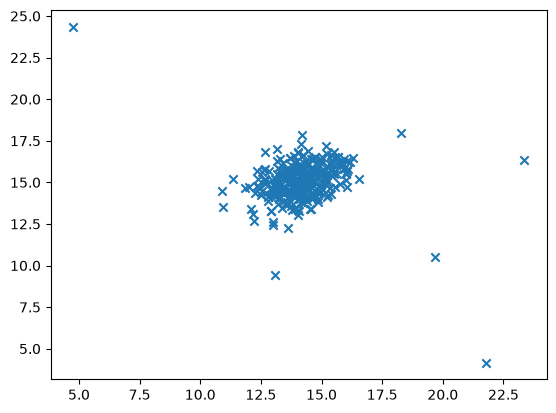

In [8]:
import scipy.io as sio
import matplotlib.pyplot as plt

data = sio.loadmat("./detection_data.mat")

X = data['X']
plt.scatter(X[...,0], X[...,1], marker='x', label='point')
plt.show()

#### 计算均值和方差，利用numpy库

In [9]:
import numpy as np
def estimate_parameters_for_gaussian_distribution(X):
    mu = np.mean(X, axis=0)
    sigma2 = np.var(X, axis=0)
    return mu, sigma2

#### 定义高斯概率模型

In [10]:
def gaussian_distribution(X, mu, sigma2):
    p1 = (1/np.sqrt(2*np.pi*sigma2)) * np.exp(-(X-mu) ** 2/(2*sigma2))
    p=np.prod(p1,axis=1) # 横向累乘
    return p

#### 查看高斯等高分布线

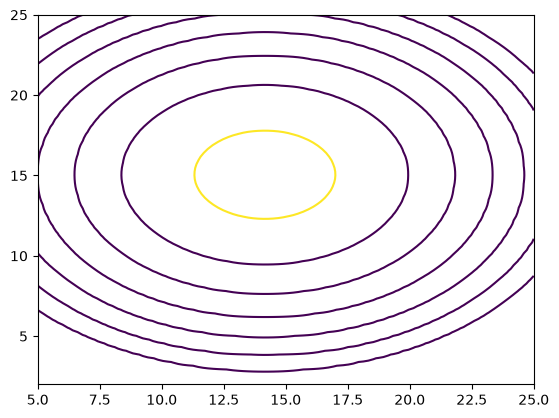

In [11]:
def visualize_contours(mu, sigma2):
    x = np.linspace(5,25,100)
    y = np.linspace(2,25,100)
    xx, yy = np.meshgrid(x, y)
    X = np.concatenate((xx.reshape(-1, 1), yy.reshape(-1 ,1)), axis=1)
    z= gaussian_distribution(X, mu, sigma2).reshape(xx.shape)
    cont_levels = [10 ** h for h in range(-20,0,3)]
    plt.contour(xx, yy, z ,cont_levels)

mu, sigma2 = estimate_parameters_for_gaussian_distribution(X)
p = gaussian_distribution(X, mu, sigma2)
visualize_contours(mu, sigma2)

#### 模型计算出的结果，进行误差分析，计算F1-score

In [12]:
def error_analysis(yp, yt):
    """
    yp: 预测值
    yt: 实际值
    """
    tp, fp, fn, tn = 0, 0, 0, 0
    for i in range(len(yp)):
        if yp[i] == yt[i]:
            if yp[i] == 1:
                tp += 1
            else:
                tn += 1
        else:
            if yp[i] == 1:
                fp += 1
            else:
                fn += 1
    precision = tp / (tp+fp) if tp + fp else 0
    recall = tp / (tp+fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return f1

#### 封装阈值选择函数，阈值从预测值的最小到最大的范围中遍历，计算F1-score选择出最佳阈值

In [13]:
def select_threshold(yval, pval):
    """
    yval: 真实值, 这里是0或1
    pval: 预测值, 是0或1的概率
    """
    epsilon = np.linspace(min(pval), max(pval), 1000)
    l = np.zeros((1, 2))
    for e in epsilon:
        ypre = (pval<e).astype(float)
        f1 = error_analysis(ypre, yval)
        l = np.concatenate((l, np.array([[e, f1]])), axis=0)
    index = np.argmax(l[...,1])
    return l[index, 0], l[index, 1]

Xval = data['Xval']
yval = data['yval']
e, f1 = select_threshold(yval.ravel(), gaussian_distribution(Xval, mu, sigma2))
print(f"最佳epsilon:{e}, F1值为{f1}")

最佳epsilon:9.00756861641923e-05, F1值为0.8750000000000001


#### 利用选择出来的阈值对异常值进行预测

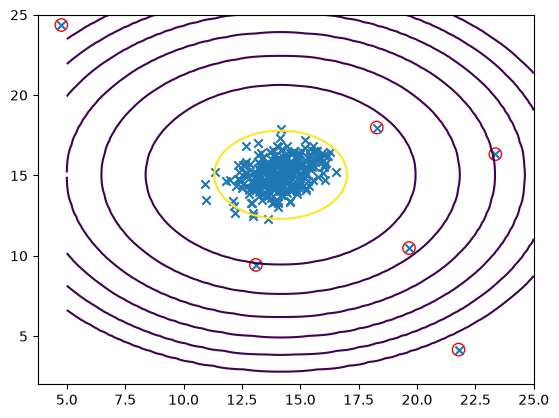

In [14]:
def detction(X, e, mu, sigma2):
    p = gaussian_distribution(X, mu, sigma2)
    anomaly_points = np.array([X[i] for i in range(len(p)) if p[i] < e])
    return anomaly_points

def visualize_dataset(X):
    plt.scatter(X[...,0], X[...,1], marker='x', label='point')

def circle_anomaly_points(X):
    # plt.scatter(X[...,0], X[...,1], marker='x', label='point')
    plt.scatter(X[..., 0], X[..., 1], s=80, facecolors='none',edgecolors='r', label='anomaly point')

anomaly_point = detction(X, e, mu, sigma2)
circle_anomaly_points(anomaly_point)
visualize_dataset(X)
visualize_contours(mu, sigma2)